# ✅ Outlier Detection & Treatment (Trimming + Z-score + Capping)
#### Dataset: placement.csv
#### Columns: cgpa, placement_exam_marks, placed
####
#### NOTE:
#### - Outliers = extreme values that can disturb model learning
#### - We will detect outliers using:
####   1) Mean ± 3*Std (Empirical Rule)
####   2) Z-score method
#### - Then handle using:
####   ✅ Trimming (remove outliers)
####   ✅ Capping (clip outliers to boundary)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# Step 1) Load Dataset
# -------------------------------
df = pd.read_csv("placement2.csv")

print("✅ Shape:", df.shape)
print("\n✅ Sample Data:\n", df.sample(5))


✅ Shape: (1000, 3)

✅ Sample Data:
      cgpa  placement_exam_marks  placed
455  6.92                  43.0       0
876  6.33                  20.0       0
781  7.17                  49.0       1
403  6.71                  83.0       0
727  7.00                  30.0       0


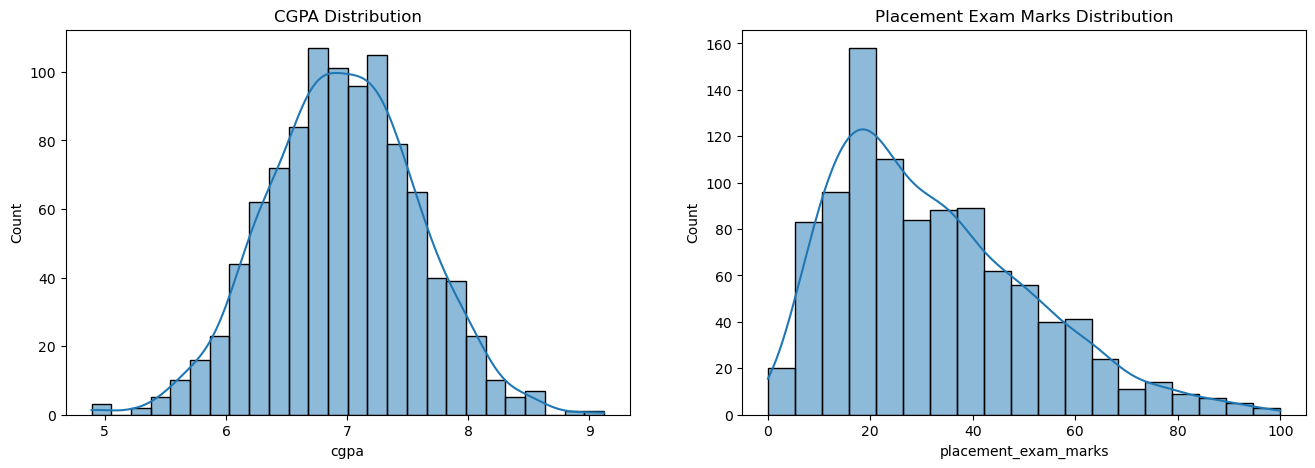


✅ Skewness of placement_exam_marks: 0.8356419499466834


In [6]:
# Step 2) Basic Distribution Plot
# -------------------------------
plt.figure(figsize=(16, 5))

plt.subplot(1, 2, 1)
sns.histplot(df["cgpa"], kde=True)
plt.title("CGPA Distribution")

plt.subplot(1, 2, 2)
sns.histplot(df["placement_exam_marks"], kde=True)
plt.title("Placement Exam Marks Distribution")

plt.show()

print("\n✅ Skewness of placement_exam_marks:", df["placement_exam_marks"].skew())


# ============================================================
# ✅ Utility Function (Summary + Limits)
# ============================================================
def get_outlier_limits(data, col, k=3):
    """
    Returns lower and upper limits using:
    mean ± k * std
    """
    mean = data[col].mean()
    std = data[col].std()
    
    lower = mean - k * std
    upper = mean + k * std
    
    return lower, upper



In [7]:
# -------------------------------
# Step 3) Calculate Boundaries for CGPA
# -------------------------------
lower_limit, upper_limit = get_outlier_limits(df, "cgpa", k=3)

print("\n✅ CGPA Stats:")
print("Mean:", df["cgpa"].mean())
print("Std :", df["cgpa"].std())
print("Min :", df["cgpa"].min())
print("Max :", df["cgpa"].max())

print("\n✅ Boundary Values (mean ± 3*std):")
print("Lowest allowed :", lower_limit)
print("Highest allowed:", upper_limit)



✅ CGPA Stats:
Mean: 6.96124
Std : 0.6158978751323894
Min : 4.89
Max : 9.12

✅ Boundary Values (mean ± 3*std):
Lowest allowed : 5.113546374602832
Highest allowed: 8.808933625397168


In [8]:

# -------------------------------
# Step 4) Find Outliers (CGPA)
# -------------------------------
outliers = df[(df["cgpa"] < lower_limit) | (df["cgpa"] > upper_limit)]
print("\n✅ Outliers in CGPA:")
print(outliers)

print("\n✅ Total outliers:", outliers.shape[0])



✅ Outliers in CGPA:
     cgpa  placement_exam_marks  placed
485  4.92                  44.0       1
995  8.87                  44.0       1
996  9.12                  65.0       1
997  4.89                  34.0       0
999  4.90                  10.0       1

✅ Total outliers: 5


# ✅ METHOD 1: Trimming (Remove Outliers)


In [9]:
trimmed_df = df[(df["cgpa"] >= lower_limit) & (df["cgpa"] <= upper_limit)].copy()

print("\n✅ After Trimming Shape:", trimmed_df.shape)



✅ After Trimming Shape: (995, 3)


# ✅ METHOD 2: Z-score Outlier Detection
### (Z = (x - mean) / std)
### Outlier if |z| > 3

In [10]:
df_z = df.copy()
df_z["cgpa_zscore"] = (df_z["cgpa"] - df_z["cgpa"].mean()) / df_z["cgpa"].std()

z_outliers = df_z[(df_z["cgpa_zscore"] > 3) | (df_z["cgpa_zscore"] < -3)]

print("\n✅ Z-score Outliers:")
print(z_outliers)

print("\n✅ Total Z-score outliers:", z_outliers.shape[0])


# Trimming using Z-score
trimmed_df_z = df_z[(df_z["cgpa_zscore"] >= -3) & (df_z["cgpa_zscore"] <= 3)].copy()

print("\n✅ After Z-score Trimming Shape:", trimmed_df_z.shape)


✅ Z-score Outliers:
     cgpa  placement_exam_marks  placed  cgpa_zscore
485  4.92                  44.0       1    -3.314251
995  8.87                  44.0       1     3.099150
996  9.12                  65.0       1     3.505062
997  4.89                  34.0       0    -3.362960
999  4.90                  10.0       1    -3.346724

✅ Total Z-score outliers: 5

✅ After Z-score Trimming Shape: (995, 4)


# ✅ METHOD 3: Capping (Winsorization / Clipping)
### Replace outlier values by boundary values

In [11]:
capped_df = df.copy()

capped_df["cgpa"] = np.where(
    capped_df["cgpa"] > upper_limit,
    upper_limit,
    np.where(
        capped_df["cgpa"] < lower_limit,
        lower_limit,
        capped_df["cgpa"]
    )
)

print("\n✅ After Capping CGPA Describe:")
print(capped_df["cgpa"].describe())


✅ After Capping CGPA Describe:
count    1000.000000
mean        6.961499
std         0.612688
min         5.113546
25%         6.550000
50%         6.960000
75%         7.370000
max         8.808934
Name: cgpa, dtype: float64


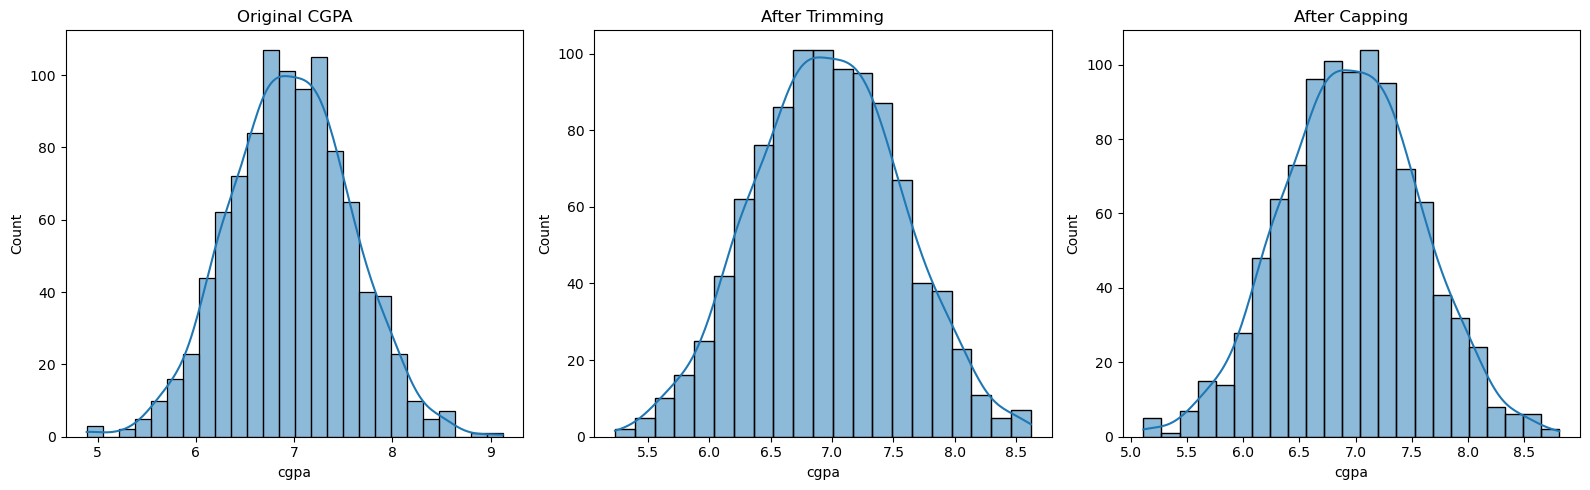

In [12]:
# ============================================================
# ✅ Compare Before vs After (CGPA Distribution)
# ============================================================
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
sns.histplot(df["cgpa"], kde=True)
plt.title("Original CGPA")

plt.subplot(1, 3, 2)
sns.histplot(trimmed_df["cgpa"], kde=True)
plt.title("After Trimming")

plt.subplot(1, 3, 3)
sns.histplot(capped_df["cgpa"], kde=True)
plt.title("After Capping")

plt.tight_layout()
plt.show()